[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adkipnis/metabeta/blob/main/demos/01-quickstart.ipynb)

# quickstart

metabeta fits Bayesian GLMMs (generalized linear mixed-effects models) with a pretrained neural
network. The network proposes posterior draws in one forward pass, and independence
Metropolis–Hastings (IMH) refines them against the exact posterior. Thus, a fit takes a fraction of
a second on a laptop and keeps the asymptotic exactness of MCMC (Markov chain Monte Carlo). On
Colab's free CPU, expect one to a few seconds.

This notebook fits lme4's `sleepstudy` end to end.

In [ ]:
%pip install -q metabeta==0.6.0

## Load a checkpoint

`from_pretrained` downloads the pretrained network weights from Hugging Face on first use
and caches them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import torch

from metabeta import Api

device = 'cuda' if torch.cuda.is_available() else 'cpu'
mb = Api.from_pretrained('gaussian', device=device)

Resolving metabeta 'normal' checkpoint from Hugging Face (adkipnis/metabeta@v1)...


Using checkpoint: /Users/alex/.cache/huggingface/hub/models--adkipnis--metabeta/snapshots/66c398ef31d65400f9ce6cff262265a9cd895a4d/metabeta-normal.pt


Loading metabeta checkpoint on cpu...


Metabeta checkpoint ready.


## The data

`sleepstudy` ([Belenky et al., 2003](https://doi.org/10.1046/j.1365-2869.2003.00337.x)) records the
reaction times of subjects under sleep restriction. We fetch the data from the
[Rdatasets](https://vincentarelbundock.github.io/Rdatasets/) archive.

In [2]:
df = sm.datasets.get_rdataset('sleepstudy', 'lme4').data
df['Subject'] = df['Subject'].astype(str)  # a label, not a number
df.head()

,Reaction,Days,Subject
0,249.5600,0,308
1,258.7047,1,308
2,250.8006,2,308
3,321.4398,3,308
4,356.8519,4,308


## Fit the model

The formula is written in lme4 syntax. By default, `sample` standardizes the
data and returns 1000 posterior draws.

In [3]:
%%time
result = mb.sample(df, formula='Reaction ~ Days + (Days | Subject)', seed=0)  # reproducible

CPU times: user 134 ms, sys: 15.3 ms, total: 149 ms
Wall time: 162 ms


## Posterior summary

- **Priors**: the checkpoint's defaults. See notebook `03-priors` on how to specify your own.
- **Fixed Effects**: posterior mean, SD (standard deviation) and quantiles. `2.5%` and `97.5%`
  bound the 95% credible interval.
- **P(>0)**: the posterior probability that the effect is positive.
- **Contr.**: posterior contraction (1 − posterior variance / prior variance). Near 1 the data
  dominate, near 0 the prior does.
- **Standard Deviations**: SDs of the random effects across subjects (and of the residual noise).
- **Correlations**: between a subject's random intercept and random slope.
- **Last line**: the diagnostics, explained at the end of this notebook.

In [4]:
print(mb.posteriorSummary(result))

Formula:  Reaction ~ Days + (Days | Subject)
n = 180   m = 18
Priors:
  Intercept ~ N(298.5, 261)
  Days ~ N(0, 48.89)
  σ_Intercept ~ HN(140.4) at mean Days
  σ_Days ~ HN(48.89)
  Corr ~ LKJ(1) at mean Days
  σ_Residual ~ HT₅(56.17)

Fixed Effects:
|           |    Mean |    SD |    2.5% |   50.0% |   97.5% |   P(>0) |   Contr. |
|-----------|---------|-------|---------|---------|---------|---------|----------|
| Intercept | 251.276 | 8.046 | 235.865 | 251.166 | 267.935 |   1.000 |    0.999 |
| Days      |  10.434 | 1.653 |   7.267 |  10.485 |  13.676 |   1.000 |    0.999 |

Standard Deviations:
|           |   Mean |    SD |   2.5% |   50.0% |   97.5% |
|-----------|--------|-------|--------|---------|---------|
| Intercept | 29.938 | 8.059 | 17.744 |  29.099 |  47.685 |
| Days      |  6.368 | 1.472 |  3.936 |   6.194 |   9.584 |
| Residual  | 25.752 | 1.535 | 22.652 |  25.714 |  28.829 |

Correlations:
|           |   Intercept |   Days |
|-----------|-------------|--------|
| Inter

### Compared with lme4

For comparison, let's have a look at lme4's REML (restricted maximum likelihood) fit of the same
formula ([Bates et al., 2015](https://doi.org/10.18637/jss.v067.i01)):

In [5]:
# lmer(Reaction ~ Days + (Days | Subject), sleepstudy) with lme4 2.0.6, as in Bates, Mächler,
# Bolker and Walker (2015), Journal of Statistical Software 67(1)
lme4 = pd.DataFrame(
    {
        'Estimate': [251.405, 10.467, 24.741, 5.922, 25.592, 0.066],
        'Std. Error': [6.825, 1.546, None, None, None, None],
    },
    index=['Intercept', 'Days', 'σ_Intercept', 'σ_Days', 'σ_Residual', 'Corr(Intercept, Days)'],
)
lme4.fillna('')

,Estimate,Std. Error
Intercept,251.405,6.825
Days,10.467,1.546
σ_Intercept,24.741,
σ_Days,5.922,
σ_Residual,25.592,
"Corr(Intercept, Days)",0.066,


On this simple data-dominated case, the Bayesian and frequentist fits agree:

- lme4's fixed effects and SDs all lie inside metabeta's 95% intervals.
- The fixed effects' posterior SDs are slightly larger than lme4's standard errors, because they
  also account for the uncertainty in the random-effect SDs.

## Random effects per subject

`rfxSummary` prints one table per random effect. Each row is a subject's deviation from the
population.

- **n**: the subject's number of rows.
- **z**: the posterior mean divided by the effect's SD. A large |z| marks an unusual subject.
- **SD ratio** (at the bottom): the spread of the subjects' posterior means, divided by the
  effect's SD. It typically falls below 1 because partial pooling shrinks subjects toward the
  population.

In [6]:
print(mb.rfxSummary(result))

Random Effects:

Intercept:
|   Group |   n |    Mean |     SD |    2.5% |   50.0% |   97.5% |     z |
|---------|-----|---------|--------|---------|---------|---------|-------|
|     308 |  10 |   2.122 | 14.809 | -27.125 |   1.889 |  29.864 |  0.07 |
|     309 |  10 | -41.513 | 14.649 | -70.429 | -41.128 | -14.066 | -1.39 |
|     310 |  10 | -40.674 | 15.059 | -71.228 | -40.183 | -13.125 | -1.36 |
|     330 |  10 |  25.557 | 15.244 |  -4.275 |  25.432 |  57.018 |  0.85 |
|     331 |  10 |  23.459 | 14.580 |  -3.342 |  23.165 |  53.162 |  0.78 |
|     332 |  10 |   9.913 | 15.021 | -18.296 |  10.004 |  41.647 |  0.33 |
|     333 |  10 |  17.706 | 14.792 | -10.335 |  17.059 |  47.256 |  0.59 |
|     334 |  10 |  -7.848 | 13.840 | -35.150 |  -7.519 |  18.436 | -0.26 |
|     335 |  10 |  -0.329 | 14.987 | -29.014 |  -0.297 |  28.549 | -0.01 |
|     337 |  10 |  36.520 | 14.830 |   9.578 |  35.980 |  66.452 |  1.22 |
|     349 |  10 | -27.053 | 14.548 | -57.051 | -26.520 |   1.157 | -0.90

## Posterior pair plot

`plotParameters` shows the posterior (green) and the prior (blue) of the global parameters.

- **Diagonal**: marginal densities.
- **Upper triangle**: posterior draws.
- **Lower triangle**: posterior density and prior contours.

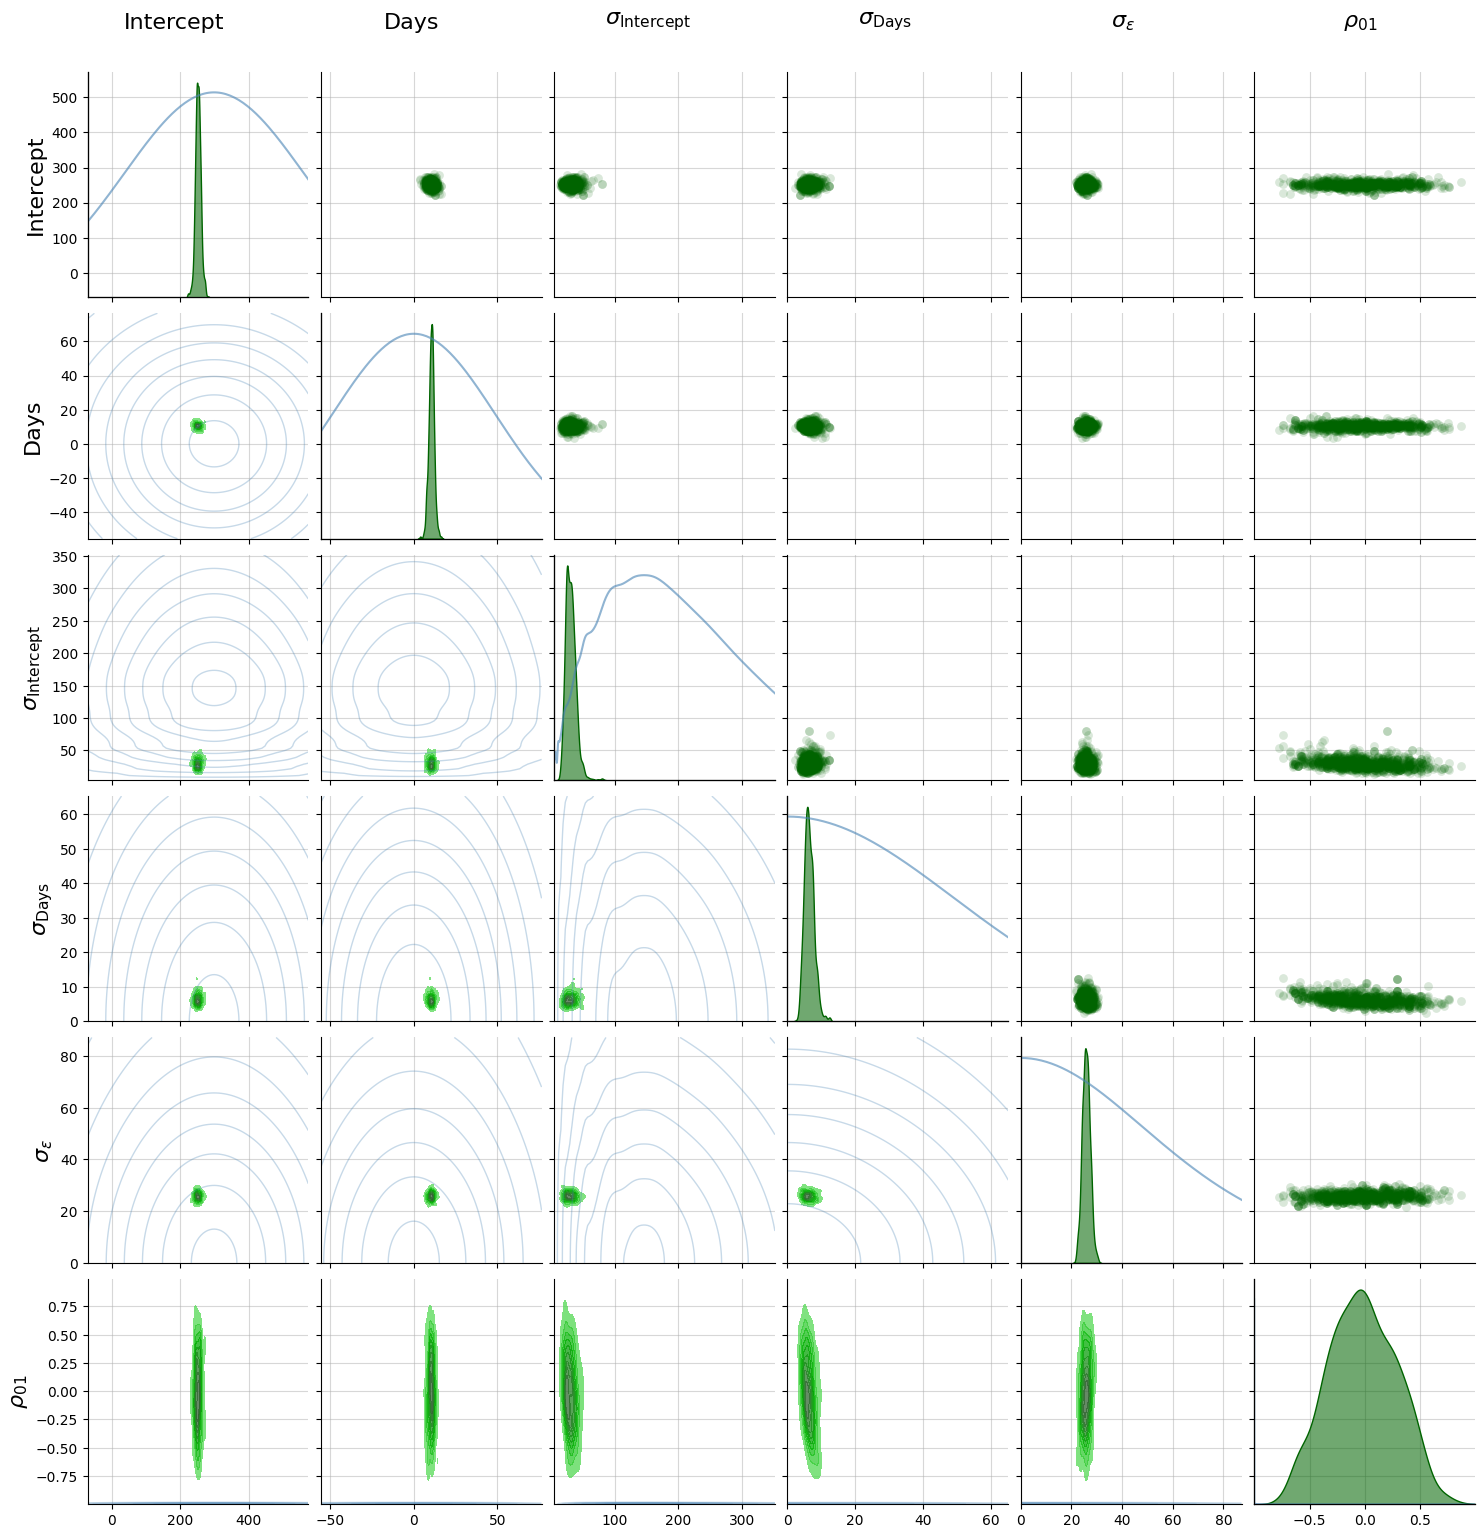

In [7]:
mb.plotParameters(result);

Sidenote: The prior of ρ₀₁, the intercept–slope correlation, piles up near −1 at the panels' edge,
and it's expected.

The prior is set at mean `Days` (4.5), where ρ₀₁ is uniform. The plot shows ρ₀₁ at `Days` = 0.
There, a subject's intercept is its value at mean `Days` minus 4.5 × its slope. The prior allows
steep slopes, so a steeper slope usually means a lower intercept at `Days` = 0.

## Fitted lines

Each panel shows one subject's data (dots), fitted line and 95% credible band.<br>
`groupDraws` returns each subject's intercept and slope draws, in the data's units.

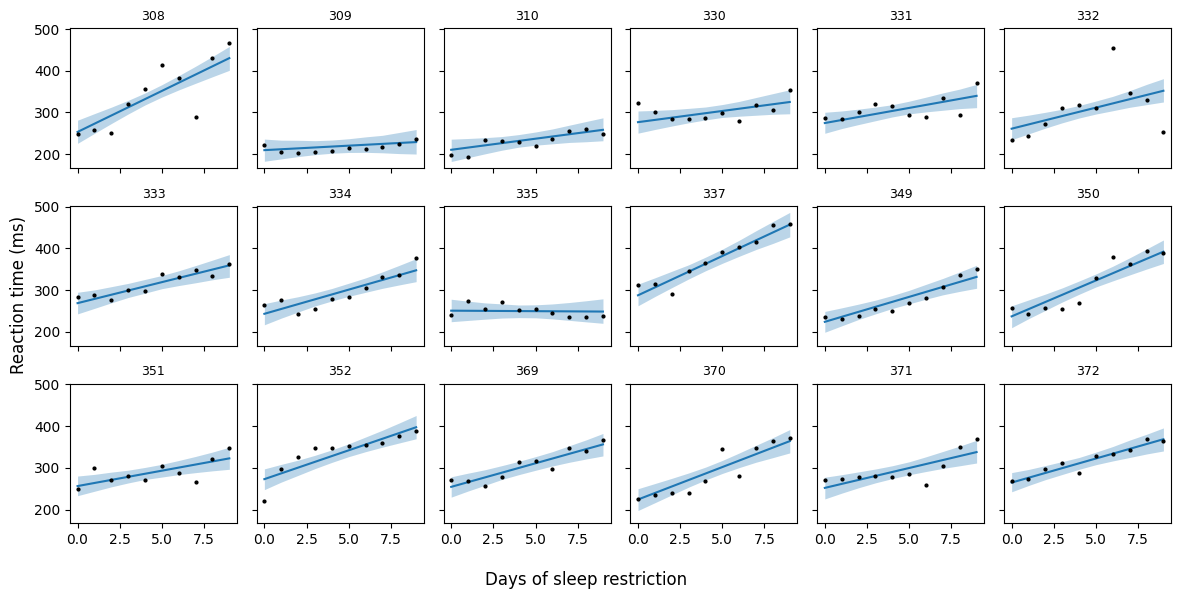

In [8]:
coef = mb.groupDraws(result)                                # (S, subjects × terms)
b0 = coef.xs('Intercept', axis=1, level='term').to_numpy()  # (S, m) subject intercepts
b1 = coef.xs('Days', axis=1, level='term').to_numpy()       # (S, m) subject slopes
days = np.arange(10)
fits = b0[..., None] + b1[..., None] * days                 # (S, m, 10) subject line per draw
lo, hi = np.percentile(fits, [2.5, 97.5], axis=0)           # (m, 10) each
mean = fits.mean(axis=0)                                    # (m, 10)

fig, axes = plt.subplots(3, 6, figsize=(12, 6), sharex=True, sharey=True)
for ax, subject, y, y_lo, y_hi in zip(axes.flat, coef.columns.unique('group'), mean, lo, hi):
    rows = df[df['Subject'] == subject]
    ax.fill_between(days, y_lo, y_hi, color='C0', alpha=0.3, lw=0)
    ax.plot(days, y, color='C0')
    ax.plot(rows['Days'], rows['Reaction'], 'k.', ms=4)
    ax.set_title(subject, fontsize=9)
fig.supxlabel('Days of sleep restriction')
fig.supylabel('Reaction time (ms)')
fig.tight_layout()

## Diagnostics

The summary's last line checks the fit. `result.safeguards` holds the first four checks.

- **acceptance**: the IMH acceptance rate. A low rate means the network's draws are far from the
  posterior.
- **min ESS**: the smallest effective sample size (ESS) over the global parameters. A low ESS can
  make the intervals too narrow.
- **PSIS k̂**: how well the network's draws match the posterior, by Pareto-smoothed importance
  sampling (PSIS). Lower is better.
- **MAP z**: the distance between the posterior mean and the maximum a posteriori (MAP) estimate,
  in posterior SDs. A large value means the network disagrees with an estimate computed without
  it.
- **R²**: the share of the variance in reaction times that the fit explains.

`sample` warns when the acceptance, the ESS or MAP z crosses its threshold. It didn't warn here,
so the draws are ready to use.

## Next steps

- `02-families`: Bernoulli and Poisson outcomes, and what to do when `sample` warns.
- `03-priors`: custom priors and Bayes factors.